## Import Libraries + Load Data

In [ ]:
# Cell 1 - stdlib only
import sys
from pathlib import Path
from itertools import combinations

In [2]:
# Cell 2 - third party
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

In [3]:
# Cell 3 - project modules
ROOT_DIR = Path.cwd().parent
sys.path.insert(0, str(ROOT_DIR))
from preprocessing.load_preprocessed_data import load_all
subjects = load_all()

## Functions

In [ ]:
def compute_pearson(data):
    """Compute Pearson correlation matrix from timeseries (timepoints x ROIs).
    Does not work in Pytorch, as we use NumPy here."""
    return np.corrcoef(data, rowvar=False)

def compute_partial(data):
    """Compute partial correlation matrix from timeseries (timepoints x ROIs)."""
    cov = np.cov(data, rowvar=False)
    precision = np.linalg.inv(cov)
    diag = np.sqrt(np.diag(precision))
    pc = -precision / np.outer(diag, diag)
    np.fill_diagonal(pc, 1.0)
    return pc


def render_fc_triplet(fc_pre, fc_post, fc_avg, roi_names, title_prefix, save_dir, fname, save):
    """
    Render three FC heatmaps side by side: pre, post, and a third (avg or delta).
    save_dir: Path object — determines which results folder to save to.
    """
    fig, axes = plt.subplots(1, 3, figsize=(33, 9))
    fc_delta = fc_post - fc_pre

    for ax, fc, label in zip(axes,
                              [fc_pre, fc_post, fc_avg],
                              ['Pre', 'Post', 'Avg (Post - Pre)']):
        vmin, vmax = (-1, 1) if label != 'Avg (Post - Pre)' else (-0.5, 0.5)
        sns.heatmap(fc,
                    xticklabels=roi_names,
                    yticklabels=roi_names,
                    cmap='coolwarm',
                    vmin=vmin, vmax=vmax,
                    center=0,
                    ax=ax)
        ax.set_title(f"{title_prefix} — {label}")
        ax.tick_params(axis='x', labelsize=7, rotation=90)
        ax.tick_params(axis='y', labelsize=7, rotation=0)

    plt.tight_layout()

    if save:
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_dir / fname, dpi=150, bbox_inches='tight')
        print(f"Saved: {save_dir / fname}")

    plt.show()


def plot_subject_fc(subject, fc_func, save_dir, save=False):
    """
    Plot pre, post, and delta FC for a single subject.
    fc_func: compute_pearson or compute_partial
    save_dir: Path to results subfolder
    """
    fc_pre   = fc_func(subject['mpre'])
    fc_post  = fc_func(subject['mpost'])
    fc_delta = fc_post - fc_pre

    render_fc_triplet(
        fc_pre, fc_post, fc_delta,
        roi_names    = subject['roi_names'],
        title_prefix = f"{subject['subject_id']} {subject['target']}",
        save_dir     = save_dir,
        fname        = f"{subject['subject_id']}_{subject['target']}_fc_heatmap.png",
        save         = save
    )


def compute_group_mean_fc(subjects, target, fc_func):
    """Compute group-mean pre, post, and delta FC for a given target."""
    target_subjects = [s for s in subjects if s['target'] == target]
    fc_pre_mean  = np.mean([fc_func(s['mpre'])  for s in target_subjects], axis=0)
    fc_post_mean = np.mean([fc_func(s['mpost']) for s in target_subjects], axis=0)
    fc_avg_mean  = fc_post_mean - fc_pre_mean
    return fc_pre_mean, fc_post_mean, fc_avg_mean

def plot_group_mean_fc(subjects, target, fc_func, save_dir, save=False, title_override=None):
    target_subjects = [s for s in subjects if s['target'] == target]
    fc_pre_mean, fc_post_mean, fc_avg_mean = compute_group_mean_fc(subjects, target, fc_func)
    title = title_override if title_override else f"{target.upper()} Group Mean (n={len(target_subjects)})"
    render_fc_triplet(
        fc_pre_mean, fc_post_mean, fc_avg_mean,
        roi_names    = target_subjects[0]['roi_names'],
        title_prefix = title,
        save_dir     = save_dir,
        fname        = f"group_mean_{target}_{(title_override or target).replace(' ', '_')}_fc_heatmap.png",
        save         = save
    )

def summarize_top_connections(fc_delta, roi_names, title, n=10):
    """Print top n increases and decreases in FC from a delta matrix."""
    records = []
    for i, j in combinations(range(len(roi_names)), 2):
        records.append({
            'roi_1':    roi_names[i],
            'roi_2':    roi_names[j],
            'delta_fc': fc_delta[i, j]
        })
    
    df = pd.DataFrame(records).sort_values('delta_fc', ascending=False)
    
    print(f"\n=== {title} ===")
    print(f"\nTop {n} INCREASES in connectivity:")
    print(df.head(n).to_string(index=False))
    print(f"\nTop {n} DECREASES in connectivity:")
    print(df.tail(n).sort_values('delta_fc').to_string(index=False))

## Pearson Correlation Heatmaps

### All Patient Heatmaps

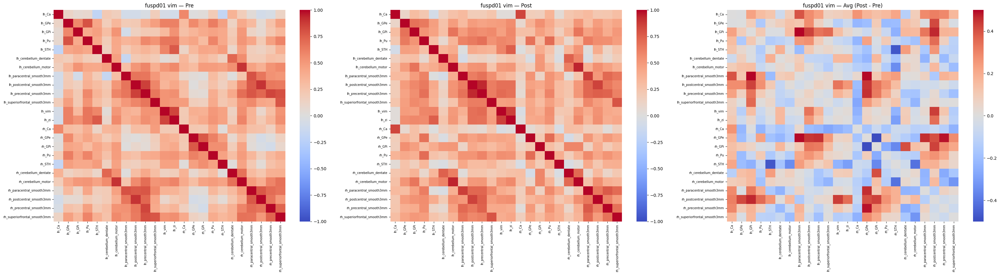

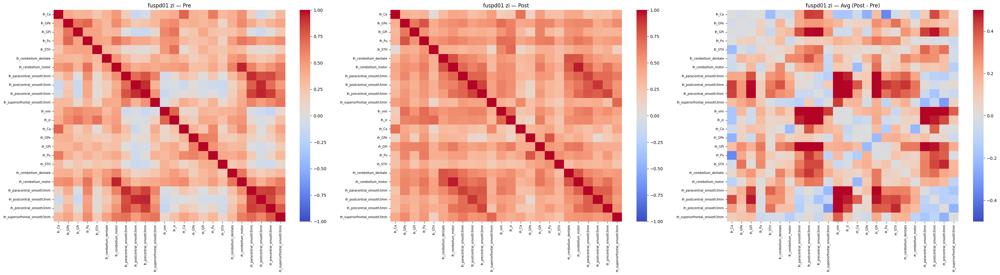

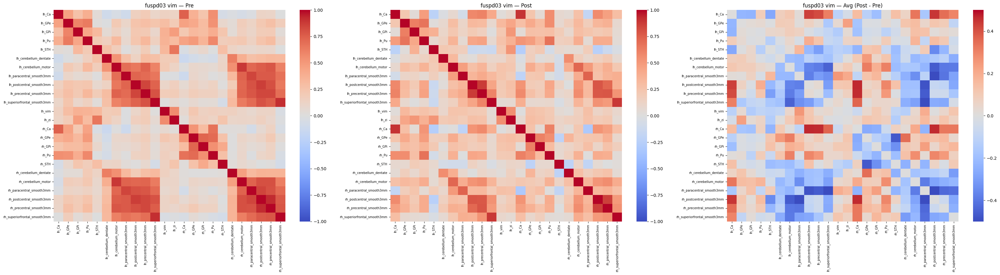

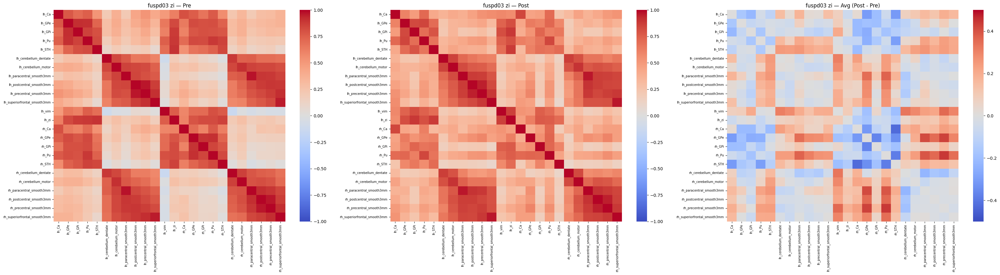

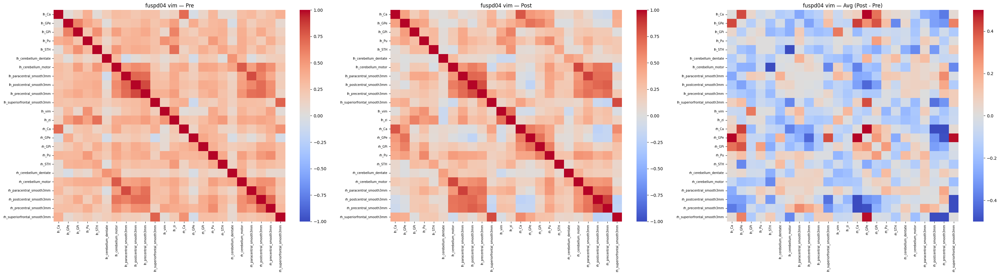

...

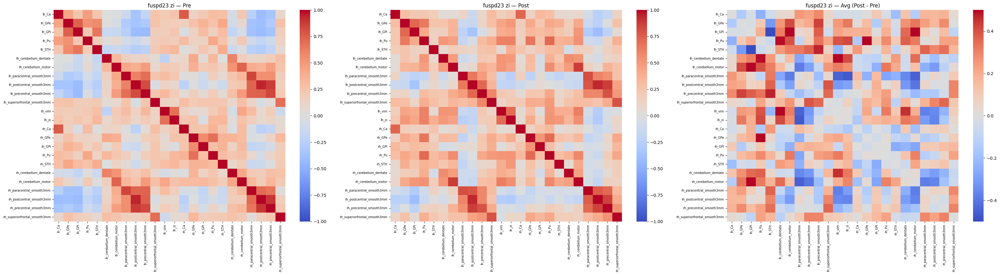

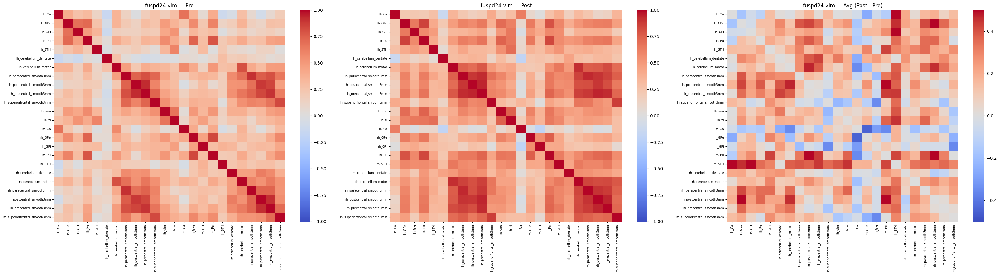

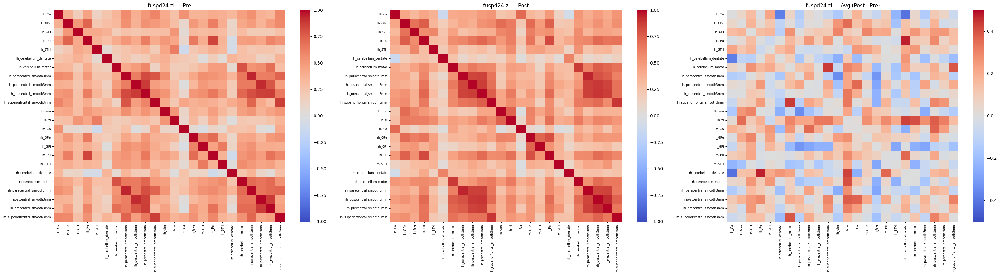

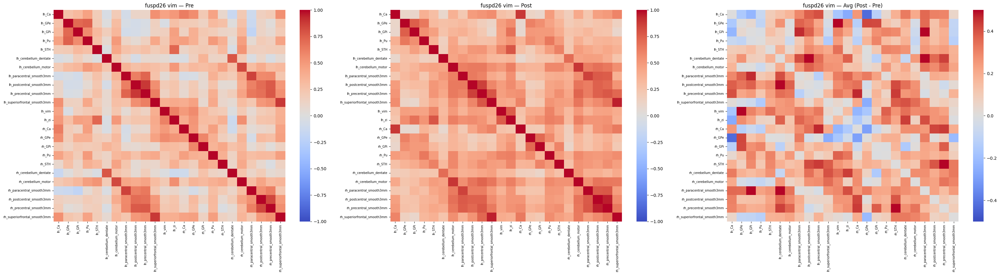

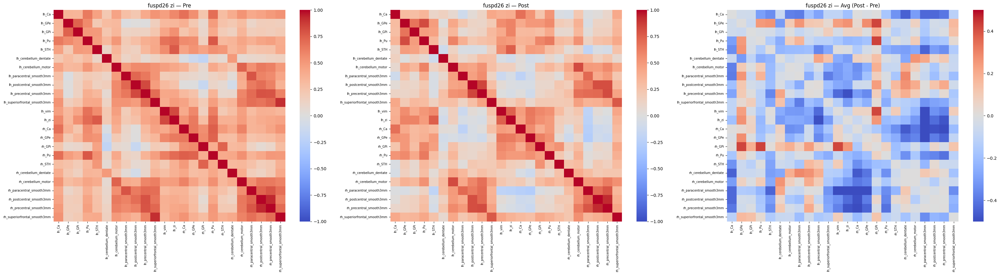

In [26]:
# --- RUN: PEARSON ---
save = False  # Set to True to save figures
pearson_dir = ROOT_DIR / "results" / "qc_heatmaps_Pearson_Corr"

for s in subjects:
    plot_subject_fc(s, compute_pearson, pearson_dir, save)

### Group-Mean Heatmap

Overall group mean separated by VIM vs ZI treatment.

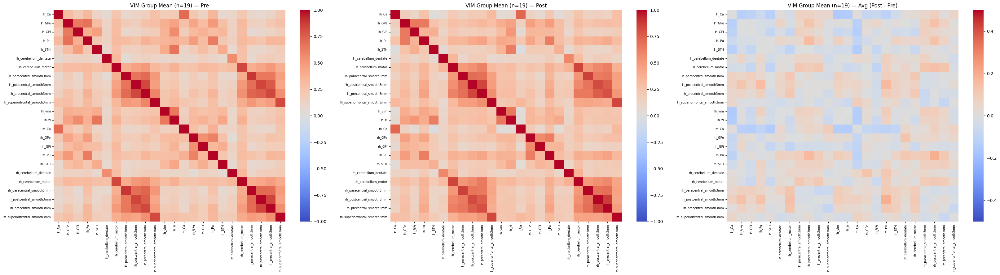

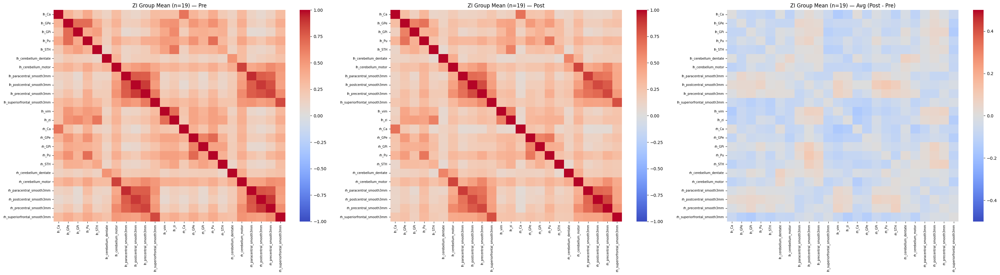

In [27]:
# --- RUN: PEARSON ---
save = False  # Set to True to save figures
pearson_dir = ROOT_DIR / "results" / "qc_heatmaps_Pearson_Corr"

for target in ['vim', 'zi']:
    plot_group_mean_fc(subjects, target, compute_pearson, pearson_dir, save=save)

Overall group mean separated by VIM vs ZI treatment AND order of treatment (VIM first or ZI first).

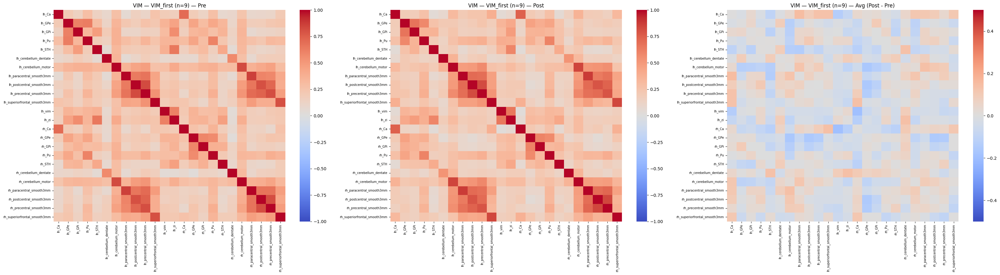

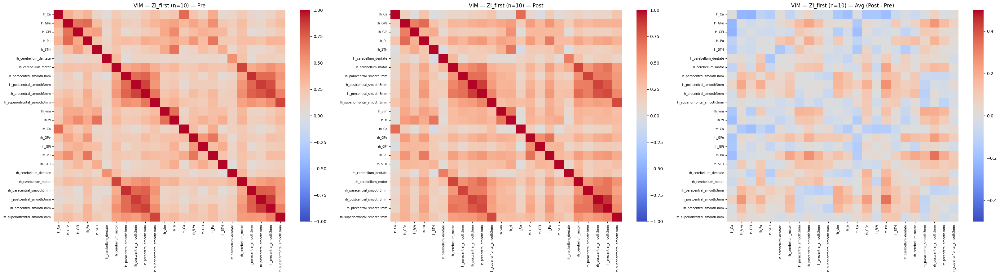

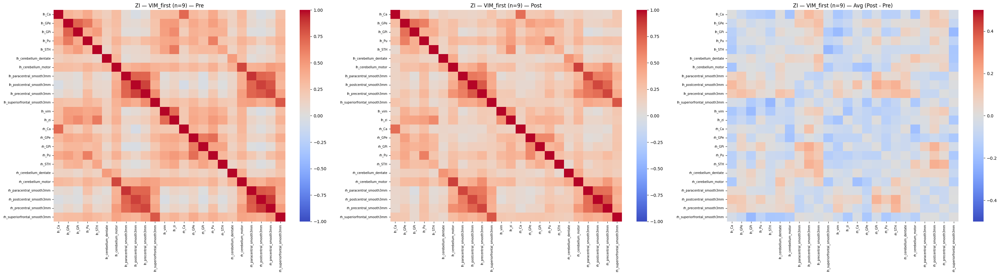

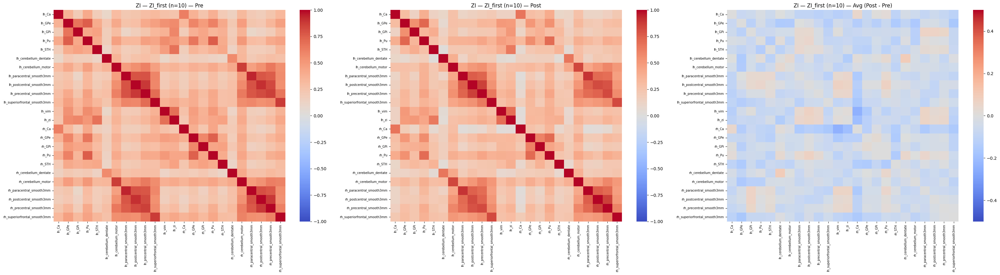

In [28]:
save = False  # Set to True to save figures
pearson_dir = ROOT_DIR / "results" / "qc_heatmaps_Pearson_Corr"

for target in ['vim', 'zi']:
    for group in ['VIM_first', 'ZI_first']:
        subset = [s for s in subjects if s['target'] == target and s['group'] == group]
        plot_group_mean_fc(subset, target, compute_pearson, pearson_dir, save=save,
                           title_override=f"{target.upper()} — {group} (n={len(subset)})")

### Quantify Pearson Correlation

In [25]:
roi_names = subjects[0]['roi_names']

for target in ['vim', 'zi']:
    for group in ['VIM_first', 'ZI_first']:
        subset = [s for s in subjects if s['target'] == target and s['group'] == group]
        title = f"{target.upper()} — {group} (n={len(subset)})"
        _, _, fc_delta = compute_group_mean_fc(subset, target, compute_pearson)
        summarize_top_connections(fc_delta, roi_names, title)


=== VIM — VIM_first (n=9) ===

Top 10 INCREASES in connectivity:
                       roi_1                        roi_2  delta_fc
                       lh_Ca     lh_paracentral_smooth3mm  0.151830
lh_superiorfrontal_smooth3mm                        rh_Ca  0.140257
         lh_cerebellum_motor     rh_paracentral_smooth3mm  0.138167
                       lh_zi        rh_cerebellum_dentate  0.137350
                      lh_STH        rh_cerebellum_dentate  0.135251
                       lh_Ca lh_superiorfrontal_smooth3mm  0.130401
                       lh_Ca      lh_precentral_smooth3mm  0.130300
         lh_cerebellum_motor     lh_paracentral_smooth3mm  0.125503
    lh_paracentral_smooth3mm          rh_cerebellum_motor  0.119513
                       lh_Ca          rh_cerebellum_motor  0.116602

Top 10 DECREASES in connectivity:
                   roi_1                    roi_2  delta_fc
                  lh_vim                    rh_Ca -0.192764
     lh_cerebellum_motor       

## Partial Correlation Heatmaps

### All Patient Heatmaps

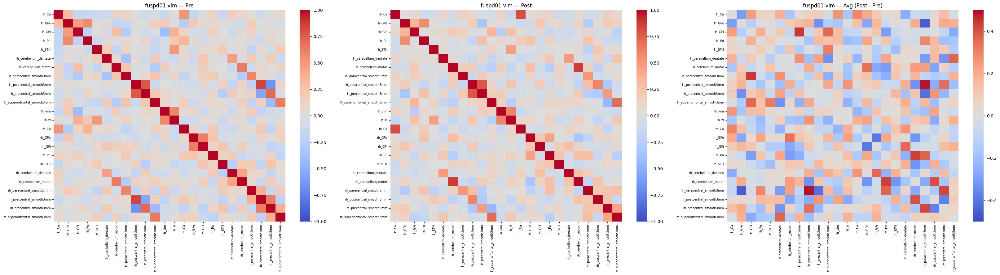

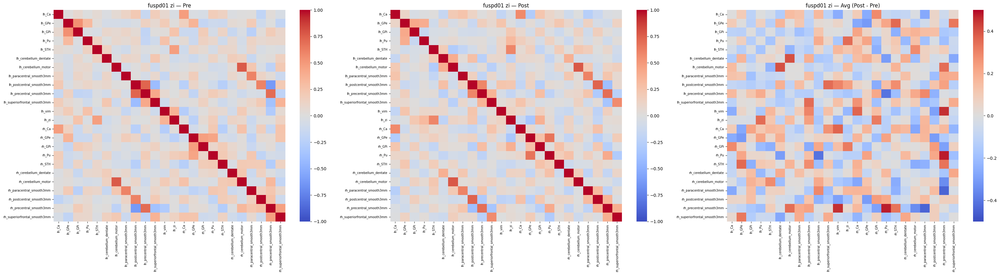

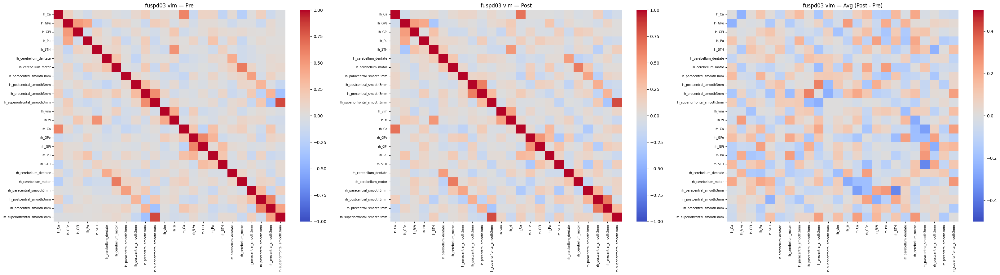

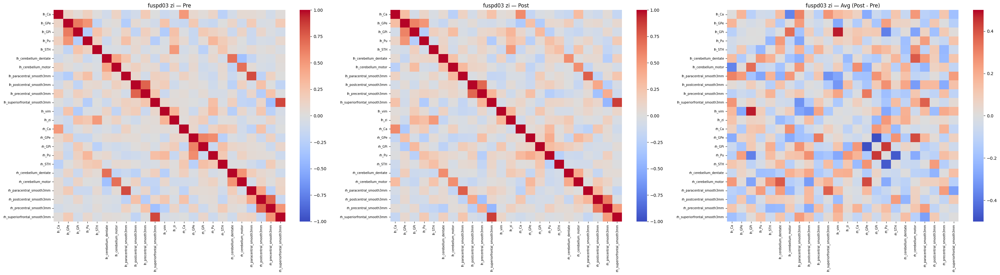

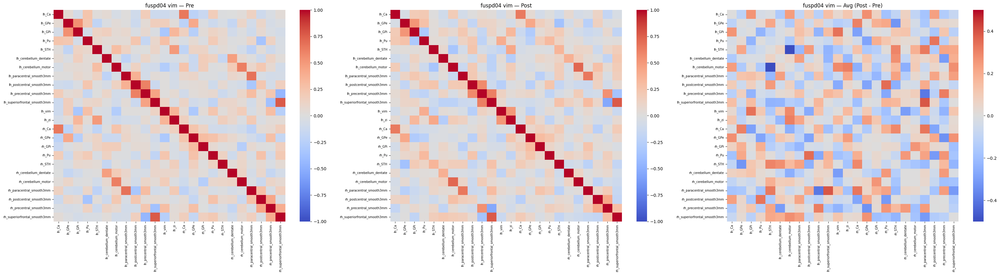

...

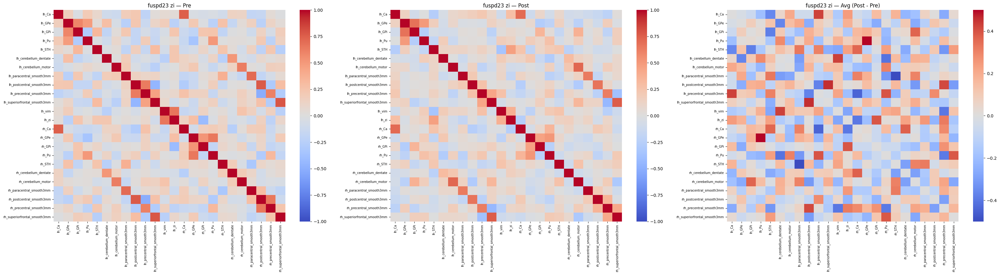

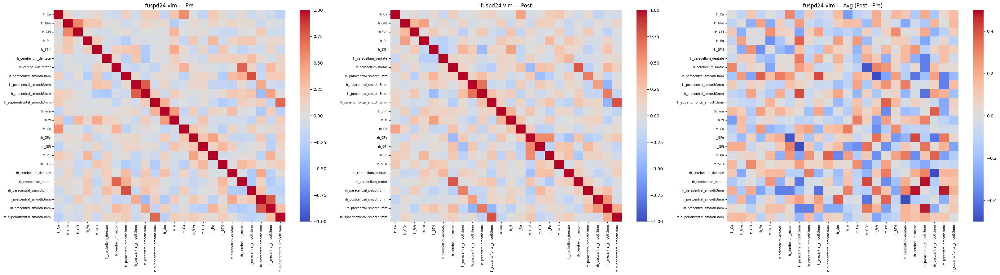

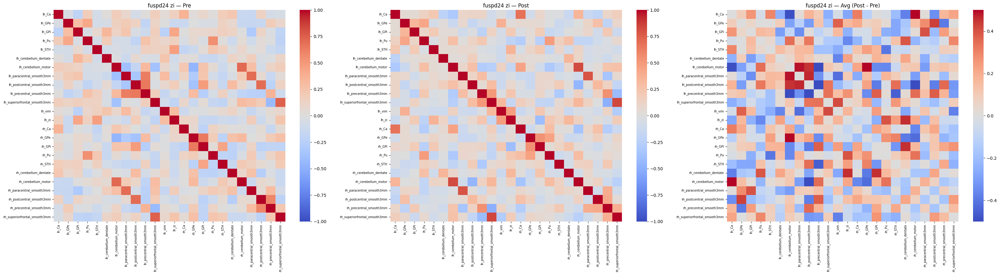

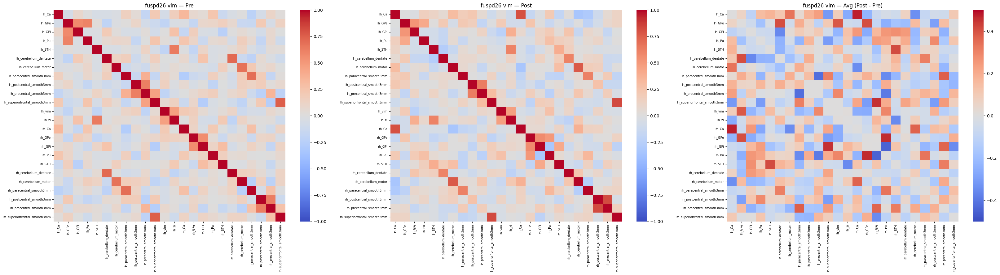

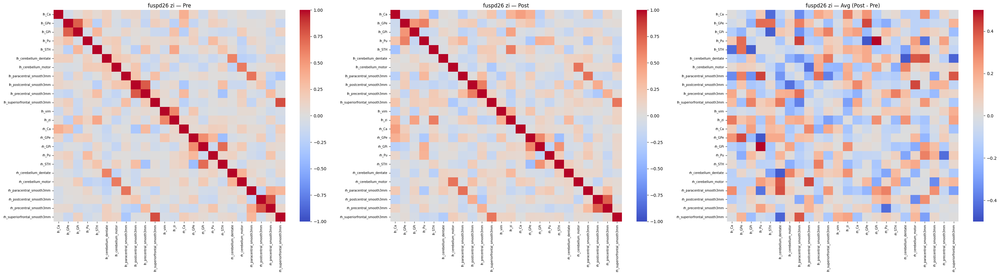

In [18]:
# --- RUN: PARTIAL CORRELATION ---
save = False  # Set to True to save figures
partial_dir = ROOT_DIR / "results" / "qc_heatmaps_Partial_Corr"

for s in subjects:
    plot_subject_fc(s, compute_partial, partial_dir, save)

### Group-Mean Heatmaps

Overall group mean separated by VIM vs ZI treatment.

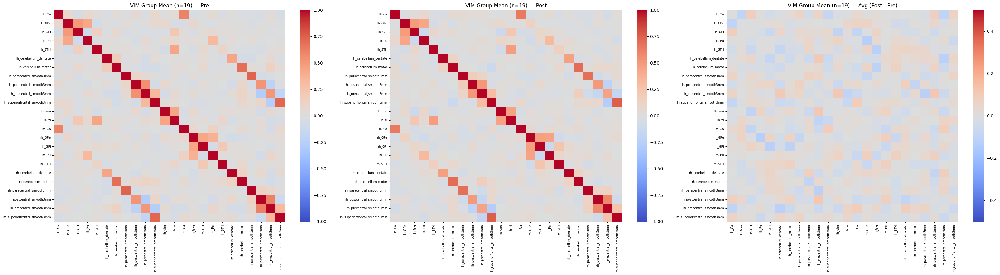

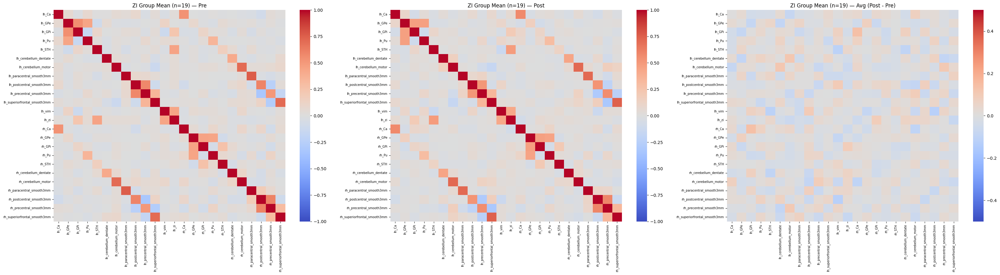

In [19]:
# --- RUN: PARTIAL CORRELATION ---
save = False  # Set to True to save figures
partial_dir = ROOT_DIR / "results" / "qc_heatmaps_Partial_Corr"

for target in ['vim', 'zi']:
    plot_group_mean_fc(subjects, target, compute_partial, partial_dir, save)

Overall group mean separated by VIM vs ZI treatment AND order of treatment (VIM first or ZI first).

Saved: c:\Users\USER\Documents\GitHub\LIFUS-BRICK\results\qc_heatmaps_Partial_Corr\group_mean_vim_VIM_—_VIM_first_(n=9)_fc_heatmap.png


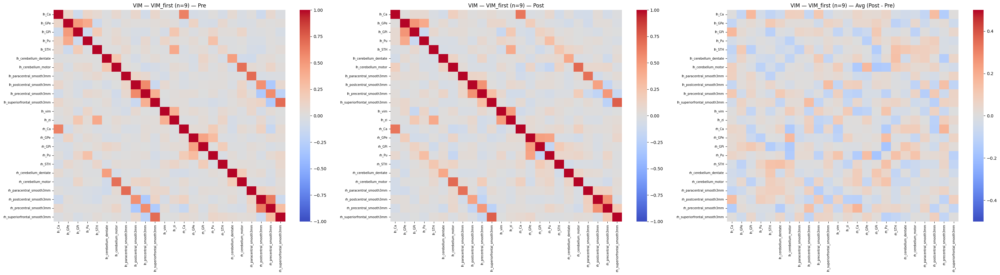

Saved: c:\Users\USER\Documents\GitHub\LIFUS-BRICK\results\qc_heatmaps_Partial_Corr\group_mean_vim_VIM_—_ZI_first_(n=10)_fc_heatmap.png


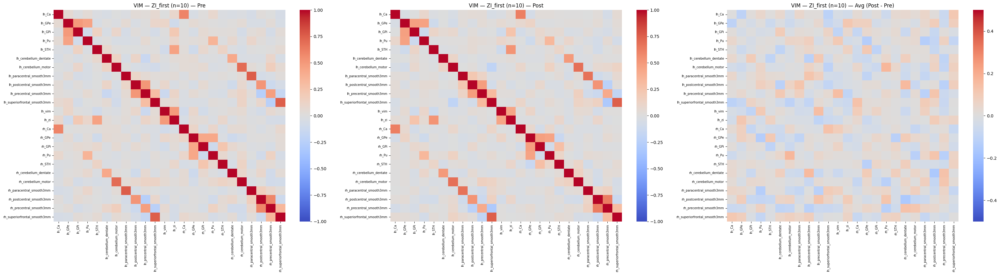

Saved: c:\Users\USER\Documents\GitHub\LIFUS-BRICK\results\qc_heatmaps_Partial_Corr\group_mean_zi_ZI_—_VIM_first_(n=9)_fc_heatmap.png


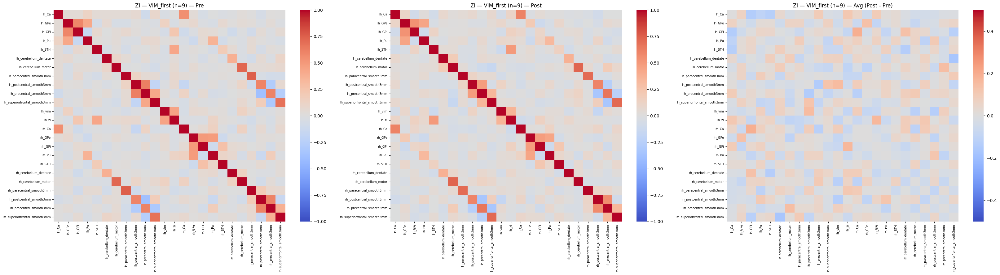

Saved: c:\Users\USER\Documents\GitHub\LIFUS-BRICK\results\qc_heatmaps_Partial_Corr\group_mean_zi_ZI_—_ZI_first_(n=10)_fc_heatmap.png


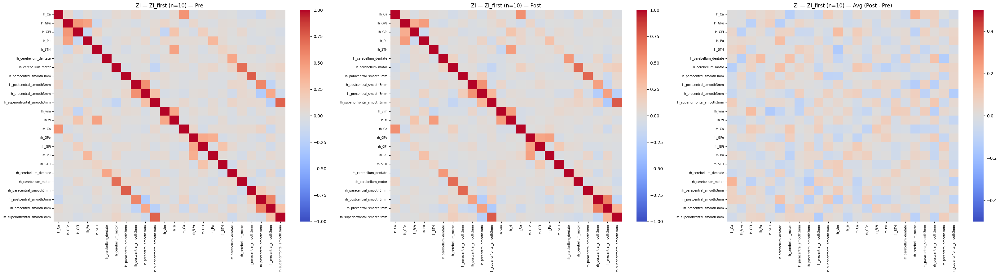

In [20]:
save = False  # Set to True to save figures
partial_dir = ROOT_DIR / "results" / "qc_heatmaps_Partial_Corr"

for target in ['vim', 'zi']:
    for group in ['VIM_first', 'ZI_first']:
        subset = [s for s in subjects if s['target'] == target and s['group'] == group]
        plot_group_mean_fc(subset, target, compute_partial, partial_dir, save=save,
                           title_override=f"{target.upper()} — {group} (n={len(subset)})")

## Plot Bar Graphs

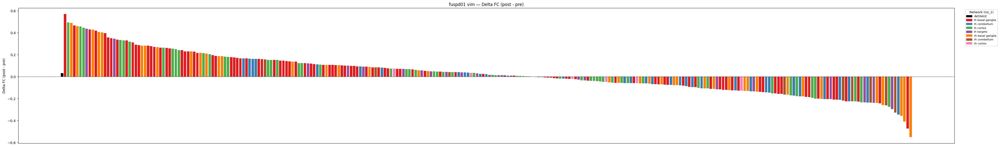

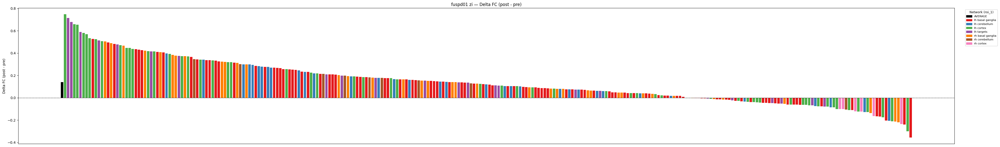

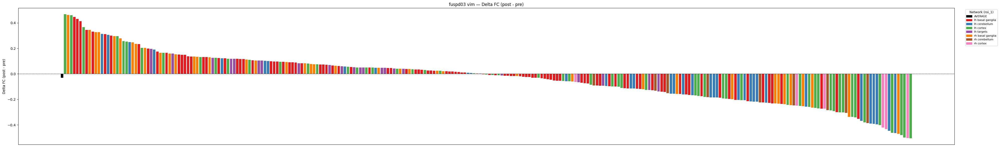

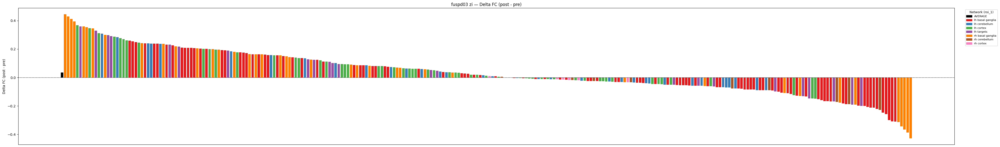

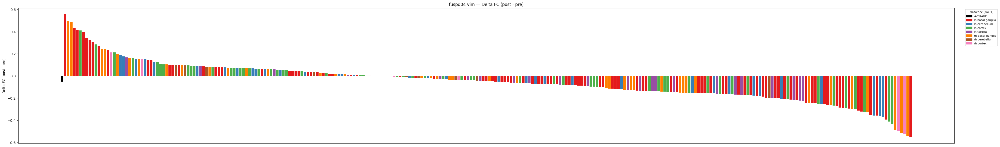

...

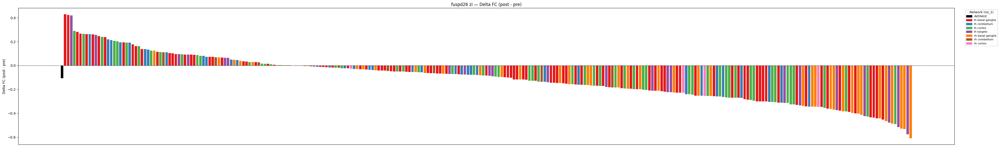

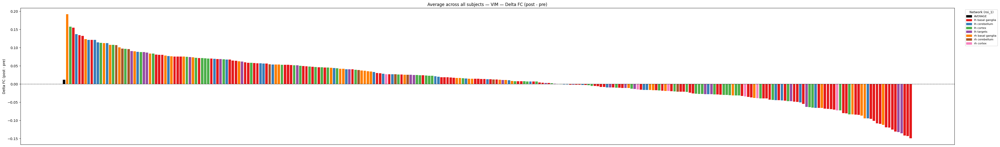

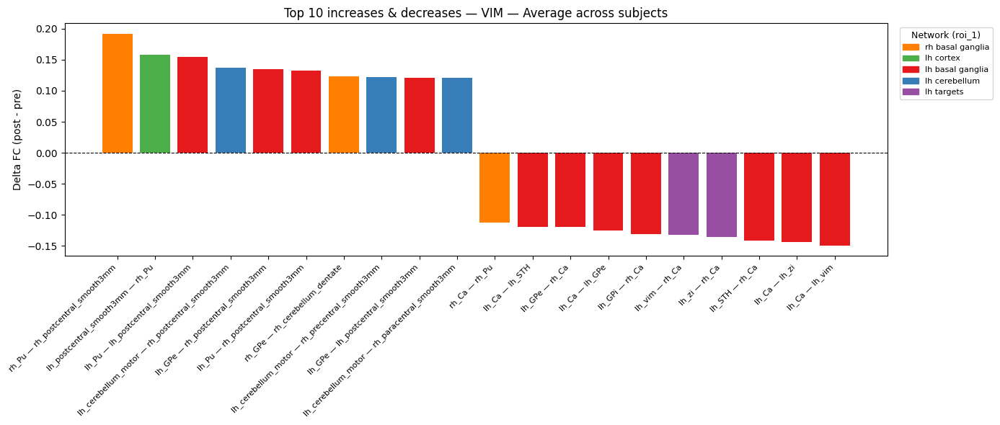

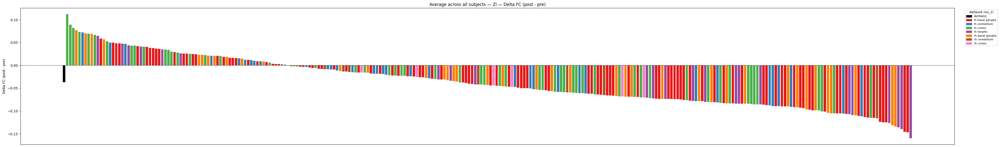

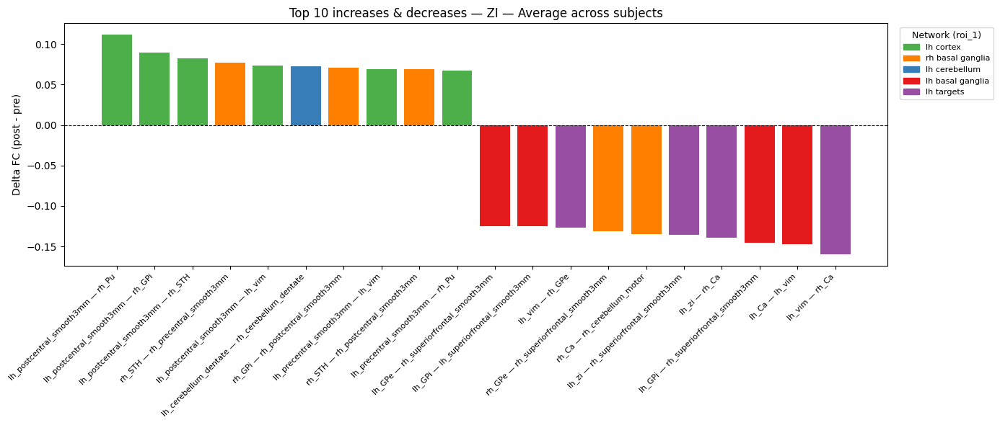

In [16]:
#Whatever is first will end up with the color of the group. Fix tomorrow

# --- NETWORK GROUPS ---
NETWORK_GROUPS = {
    'lh basal ganglia': ['lh_Ca', 'lh_GPe', 'lh_GPi', 'lh_Pu', 'lh_STH'],
    'lh cerebellum':    ['lh_cerebellum_dentate', 'lh_cerebellum_motor'],
    'lh cortex':        ['lh_paracentral_smooth3mm', 'lh_postcentral_smooth3mm',
                         'lh_precentral_smooth3mm', 'lh_superiorfrontal_smooth3mm'],
    'lh targets':       ['lh_vim', 'lh_zi'],
    'rh basal ganglia': ['rh_Ca', 'rh_GPe', 'rh_GPi', 'rh_Pu', 'rh_STH'],
    'rh cerebellum':    ['rh_cerebellum_dentate', 'rh_cerebellum_motor'],
    'rh cortex':        ['rh_paracentral_smooth3mm', 'rh_postcentral_smooth3mm',
                         'rh_precentral_smooth3mm', 'rh_superiorfrontal_smooth3mm'],
}

GROUP_COLORS = {
    'lh basal ganglia': '#e41a1c',
    'lh cerebellum':    '#377eb8',
    'lh cortex':        '#4daf4a',
    'lh targets':       '#984ea3',
    'rh basal ganglia': '#ff7f00',
    'rh cerebellum':    '#a65628',
    'rh cortex':        '#f781bf',
}

def get_group(roi):
    for group, members in NETWORK_GROUPS.items():
        if roi in members:
            return group
    return 'other'

def get_pair_color(roi_1, roi_2):
    """Color by the group of roi_1."""
    return GROUP_COLORS.get(get_group(roi_1), 'gray')

def compute_delta_fc(subject):
    fc_pre  = np.corrcoef(subject['mpre'],  rowvar=False)
    fc_post = np.corrcoef(subject['mpost'], rowvar=False)
    return fc_post - fc_pre

def build_delta_df(subject):
    delta = compute_delta_fc(subject)
    roi_names = subject['roi_names']
    records = []
    for i, j in combinations(range(len(roi_names)), 2):
        records.append({
            'roi_1':    roi_names[i],
            'roi_2':    roi_names[j],
            'pair':     f"{roi_names[i]} — {roi_names[j]}",
            'delta_fc': delta[i, j],
            'group':    get_group(roi_names[i])
        })
    return pd.DataFrame(records)

LEGEND_HANDLES = [Patch(color='black', label='AVERAGE')] + \
                 [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS]

def plot_delta_fc(df, title, show_labels=False):
    df = df.sort_values('delta_fc', ascending=False).reset_index(drop=True)

    avg = df['delta_fc'].mean()
    avg_row = pd.DataFrame([{'roi_1': 'avg', 'roi_2': 'avg', 'pair': 'AVERAGE',
                              'delta_fc': avg, 'group': 'avg'}])
    df_plot = pd.concat([avg_row, df], ignore_index=True)

    colors = ['black'] + [get_pair_color(r1, r2) for r1, r2 in zip(df['roi_1'], df['roi_2'])]

    fig, ax = plt.subplots(figsize=(40, 6))
    ax.bar(range(len(df_plot)), df_plot['delta_fc'], color=colors, width=0.8)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

    if show_labels:
        ax.set_xticks(range(len(df_plot)))
        ax.set_xticklabels(df_plot['pair'], rotation=90, fontsize=6)
    else:
        ax.set_xticks([])

    ax.set_ylabel('Delta FC (post - pre)')
    ax.set_title(title)
    ax.legend(handles=LEGEND_HANDLES, title='Network (roi_1)',
              bbox_to_anchor=(1.01, 1), loc='upper left',
              fontsize=8, title_fontsize=9)

    plt.tight_layout()
    plt.show()

def plot_top20(df, title):
    top10_increase = df.nlargest(10, 'delta_fc')
    top10_decrease = df.nsmallest(10, 'delta_fc')
    top20 = pd.concat([top10_increase, top10_decrease]).sort_values(
        'delta_fc', ascending=False).reset_index(drop=True)

    colors = [get_pair_color(r1, r2) for r1, r2 in zip(top20['roi_1'], top20['roi_2'])]

    present_groups = list(dict.fromkeys(top20['group'].tolist()))
    legend_handles = [Patch(color=GROUP_COLORS[g], label=g)
                      for g in present_groups if g in GROUP_COLORS]

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.bar(range(len(top20)), top20['delta_fc'], color=colors)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_xticks(range(len(top20)))
    ax.set_xticklabels(top20['pair'], rotation=45, ha='right', fontsize=8)
    ax.set_ylabel('Delta FC (post - pre)')
    ax.set_title(title)
    ax.legend(handles=legend_handles, title='Network (roi_1)',
              bbox_to_anchor=(1.01, 1), loc='upper left',
              fontsize=8, title_fontsize=9)

    plt.tight_layout()
    plt.show()

# --- PER SUBJECT PLOTS ---
for s in subjects:
    df = build_delta_df(s)
    plot_delta_fc(df, f"{s['subject_id']} {s['target']} — Delta FC (post - pre)")

# --- AVERAGE ACROSS ALL SUBJECTS PER TARGET ---
for target in ['vim', 'zi']:
    target_subjects = [s for s in subjects if s['target'] == target]
    all_dfs = [build_delta_df(s) for s in target_subjects]

    avg_df = all_dfs[0][['roi_1', 'roi_2', 'pair', 'group']].copy()
    avg_df['delta_fc'] = np.mean([df['delta_fc'].values for df in all_dfs], axis=0)

    plot_delta_fc(avg_df, f"Average across all subjects — {target.upper()} — Delta FC (post - pre)")
    plot_top20(avg_df, f"Top 10 increases & decreases — {target.upper()} — Average across subjects")

If I want a challenge, find a way to map back into standard atlas parcels and put into a brain map using nilearn